## 9. Самостоятельная + домашняя работа

**Задача:** самостоятельно провести полный анализ scRNA-seq данных: от контроля качества и фильтрации клеток до кластеризации, аннотации клеточных типов и анализа генных программ.

**Формат работы:** индивидуально или в парах. Можно выбрать любой открытый scRNA-seq датасет. Рекомендуется использовать данные, содержащие несколько различных клеточных популяций.

### Задание 1. Выбор данных и контроль качества (QC)

1. Найдите открытый scRNA-seq датасет и загрузите его в `AnnData`.

In [ ]:
%pip install -q scanpy leidenalg scikit-misc "pandas==2.2.3"

In [ ]:
import scanpy as sc
import numpy as np
import matplotlib.pyplot as plt

adata = sc.read_h5ad("/content/55a75aef-bc7a-4ed0-b9de-80e3139caa49.h5ad")

print(adata)

AnnData object with n_obs × n_vars = 7618 × 21459
    obs: 'nCount_RNA', 'nFeature_RNA', 'donor_id', 'percent.mt', 'nuclear_fraction', 'author_cell_type', 'assay_ontology_term_id', 'disease_ontology_term_id', 'suspension_type', 'tissue_ontology_term_id', 'cell_type_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'development_stage_ontology_term_id', 'sex_ontology_term_id', 'tissue_type', 'is_primary_data', 'cell_type', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid'
    var: 'vst.mean', 'vst.variance', 'vst.variance.expected', 'vst.variance.standardized', 'vst.variable', 'feature_is_filtered', 'feature_name', 'feature_reference', 'feature_biotype', 'feature_length', 'feature_type'
    uns: 'author_cell_type_colors', 'citation', 'default_embedding', 'is_pre_analysis', 'organism', 'organism_ontology_term_id', 'schema_reference', 'schema_version', 'title'
    obsm: 'X_umap'


In [ ]:
from scipy import sparse

counts = adata.raw.X
values = counts.data if sparse.issparse(counts) else np.asarray(counts).ravel()

print("Целые значения:", np.allclose(values, np.rint(values)))
print("Нет отрицательных значений:", np.all(values >= 0))
print("Совпадают гены:", adata.var_names.equals(adata.raw.var_names))

Целые значения: True
Нет отрицательных значений: True
Совпадают гены: True


In [ ]:
adata = adata.raw.to_adata()
adata.var_names_make_unique()

print(adata)

AnnData object with n_obs × n_vars = 7618 × 21459
    obs: 'nCount_RNA', 'nFeature_RNA', 'donor_id', 'percent.mt', 'nuclear_fraction', 'author_cell_type', 'assay_ontology_term_id', 'disease_ontology_term_id', 'suspension_type', 'tissue_ontology_term_id', 'cell_type_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'development_stage_ontology_term_id', 'sex_ontology_term_id', 'tissue_type', 'is_primary_data', 'cell_type', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid'
    var: 'vst.mean', 'vst.variance', 'vst.variance.expected', 'vst.variance.standardized', 'vst.variable', 'feature_name', 'feature_reference', 'feature_biotype', 'feature_length', 'feature_type'
    uns: 'author_cell_type_colors', 'citation', 'default_embedding', 'is_pre_analysis', 'organism', 'organism_ontology_term_id', 'schema_reference', 'schema_version', 'title'
    obsm: 'X_umap'


Для анализа был выбран открытый датасет [EC Stream Region at 14 days of age](https://cellxgene.cziscience.com/e/24584be9-d3d5-49c3-a042-99c18fe324db.cxg/) из каталога CELLxGENE. Для дальнейшего анализа использована матрица исходных значений экспрессии, сохранённая в adata.raw.X

2. Кратко опишите выбранные данные:

  - Какие клетки или ткани исследовались?

  Исследовались клетки области энторинальной коры (entorhinal cortex) головного мозга человека (EC stream - зоны миграции молодых нейронов) у ребёнка в возрасте 14 дней

   - Какой биологический вопрос изучали авторы?

   Авторы исследовали, продолжается ли миграция молодых нейронов в энторинальную кору человека после рождения и какие типы нейронов участвуют в этом процессе
   - Сколько клеток и генов содержится в датасете?

   Датасет содержит 7 618 клеточных ядер и 21 459 генов до дополнительной фильтрации

3. Рассчитайте основные показатели QC: `total_counts`, `n_genes_by_counts`, `pct_counts_mt`.

In [ ]:
adata.var["mt"] = adata.var["feature_name"].str.startswith("MT-")

sc.pp.calculate_qc_metrics(
    adata,
    qc_vars=["mt"],
    percent_top=None,
    inplace=True
)

adata.obs[
    ["total_counts", "n_genes_by_counts", "pct_counts_mt"]
].describe().round(1)

,total_counts,n_genes_by_counts,pct_counts_mt
count,7618.0,7618.0,7618.0
mean,4470.8,2207.2,0.5
std,2572.8,749.6,0.3
min,1575.0,922.0,0.0
25%,2921.0,1684.0,0.3
50%,3966.0,2101.0,0.4
75%,5300.8,2578.0,0.6
max,50124.0,8619.0,5.3


4. Постройте графики распределения этих показателей (violin plots, scatter plots).

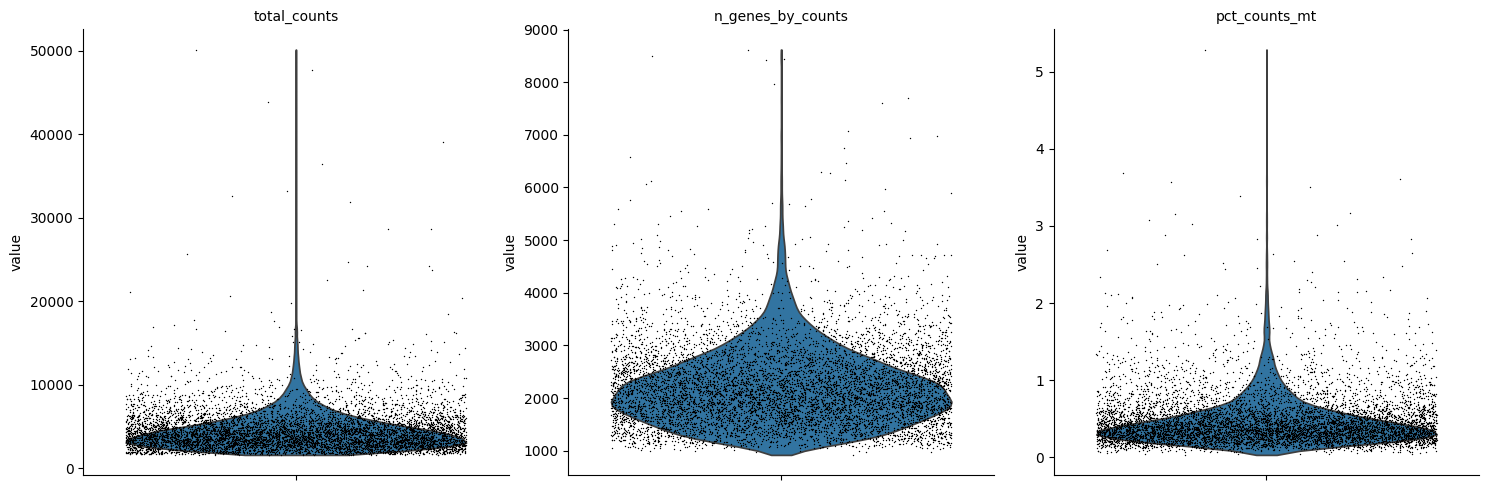

In [ ]:
metrics = ["total_counts", "n_genes_by_counts", "pct_counts_mt"]

sc.pl.violin(
    adata,
    metrics,
    jitter=0.4,
    multi_panel=True
)

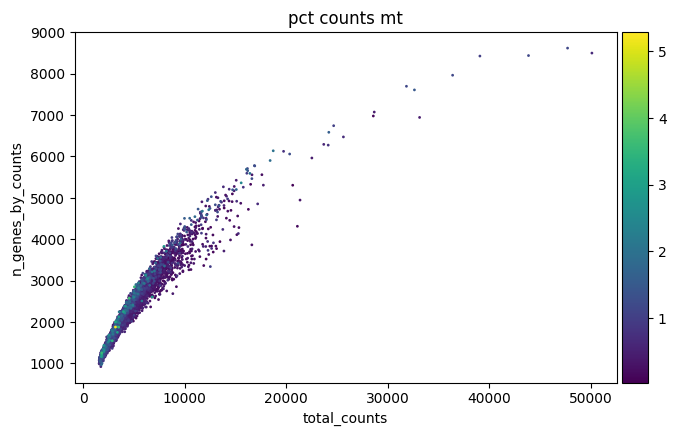

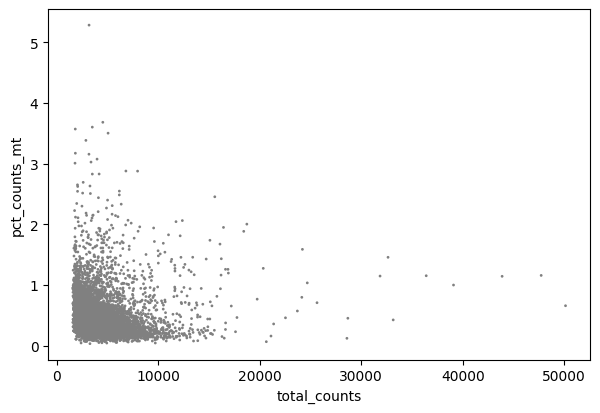

In [ ]:
sc.pl.scatter(
    adata,
    x="total_counts",
    y="n_genes_by_counts",
    color="pct_counts_mt"
)

sc.pl.scatter(
    adata,
    x="total_counts",
    y="pct_counts_mt"
)

По графикам видно, что  основная часть данных имеет достаточно однородные QC-показатели, однако присутствуют выбросы, которые необходимо учитывать при выборе порогов фильтрации

5. Выберите пороги фильтрации и удалите клетки низкого качества, а также редко обнаруживаемые гены.

Для выбора порогов посмотрим сначала на таблицу квантилей:

In [ ]:
adata.obs[
    ["total_counts", "n_genes_by_counts", "pct_counts_mt"]
].quantile([0, 0.01, 0.05, 0.5, 0.95, 0.99, 1]).round(2)

,total_counts,n_genes_by_counts,pct_counts_mt
0.00,1575.00,922.00,0.03
0.01,1720.17,1103.17,0.10
0.05,1963.85,1248.85,0.16
0.50,3966.00,2101.00,0.39
0.95,8610.40,3504.75,1.10
0.99,13292.43,4701.49,1.83
1.00,50124.00,8619.00,5.29


Выбранные пороги:

n_genes_by_counts	1 100-5 000
* 1 100 генов - примерно соответствует первому процентилю, поэтому удаляем только нижний хвост распределения
* 5 000 генов - немного выше 99го процентиля, что позволяет исключить наиболее выраженные выбросы

total_counts	1 700–15 000
* 1 700 UMI - близко к первому процентилю
* 15 000 UMI - выше 99го процентиля, позволяет оставить большинство наблюдений

pct_counts_mt	не более 2% - анализируются отдельные ядра клеток мозга, для которых характерна низкая доля митохондриальных транскриптов

Также удалим редко обнаруживаемые гены (Ген должен обнаруживаться не менее чем в 3 ядрах)

In [ ]:
#сохраним количество клеток и генов до фильтрации
n_cells_before = adata.n_obs
n_genes_before = adata.n_vars

sc.pp.filter_cells(adata, min_genes=1100)
adata = adata[
    (adata.obs["n_genes_by_counts"] < 5000) &
    (adata.obs["total_counts"] >= 1700) &
    (adata.obs["total_counts"] < 15000) &
    (adata.obs["pct_counts_mt"] < 2)].copy()
sc.pp.filter_genes(adata, min_cells=3)

6. Покажите, сколько клеток и генов осталось после фильтрации.

In [ ]:
print("До фильтрации:")
print("Ядер:", n_cells_before)
print("Генов:", n_genes_before)

print("\nПосле фильтрации:")
print("Ядер:", adata.n_obs)
print("Генов:", adata.n_vars)

print("\nУдалено ядер:", n_cells_before - adata.n_obs)
print("Удалено генов:", n_genes_before - adata.n_vars)

До фильтрации:
Ядер: 7618
Генов: 21459

После фильтрации:
Ядер: 7415
Генов: 18515

Удалено ядер: 203
Удалено генов: 2944


### Задание 2. Нормализация и высоковариабельные гены (HVG)

1. Выполните нормализацию и логарифмирование экспрессии.

In [ ]:
adata.layers["counts"] = adata.X.copy()
sc.pp.normalize_total(adata, target_sum=1e4)

sc.pp.log1p(adata)

2. Найдите высоковариабельные гены с помощью `sc.pp.highly_variable_genes()`.

In [ ]:
sc.pp.highly_variable_genes(
    adata,
    layer="counts",
    flavor="seurat_v3",
    n_top_genes=2000
)

print("Число HVG:", adata.var["highly_variable"].sum())

Число HVG: 2000


3. Постройте график HVG

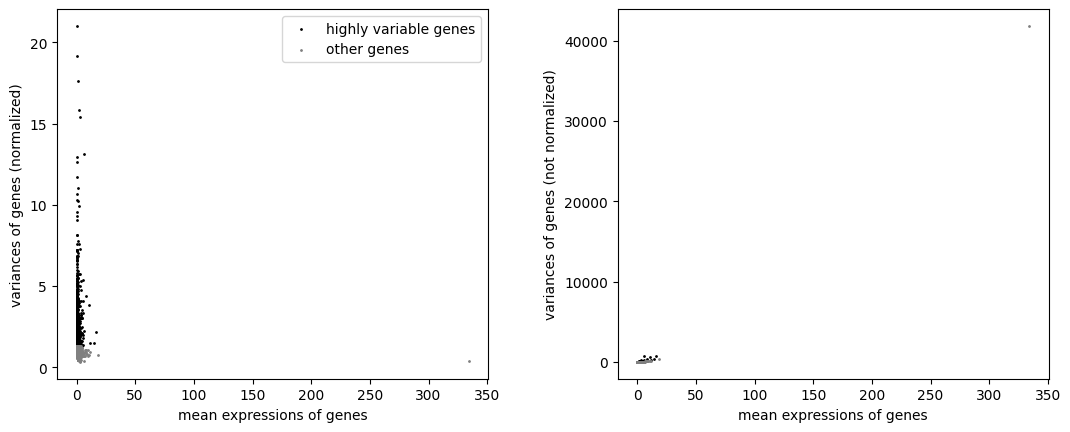

In [ ]:
sc.pl.highly_variable_genes(adata)

4. Покажите, сколько генов было выбрано.

Для дальнейшего анализа были выбраны 2000 высоковариабельных генов (HVG) с помощью метода `seurat_v3`. Такое количество является распространённым выбором при анализе scRNA-seq и позволяет уменьшить влияние малоинформативных генов, сохраняя основные различия между клеточными популяциями

**Вопрос:** зачем мы выбираем HVG и почему не обязательно использовать все гены для PCA и кластеризации?

HVG выбирают потому что их экспрессия значительно различается между клетками и может отражать биологические различия между клеточными типами

Использовать все гены для PCA и кластеризации необязательно, тк многие гены имеют низкую вариабельность и не помогают различать клеточные популяции, а только добавляют шум в анализ. Отбор HVG позволяет уменьшить размерность данных, снизить влияние шума, ускорить вычисления и лучше выделить различия между клеточными популяциями

5. Выведите 10 наиболее высоковариабельных генов и попробуйте выяснить, какие функции они выполняют.

In [ ]:
top10_hvg = (
    adata.var[adata.var["highly_variable"]]
    .sort_values("highly_variable_rank")
    .head(10)
)

top10_hvg[["feature_name", "highly_variable_rank", "variances_norm"]]

,feature_name,highly_variable_rank,variances_norm
ENSG00000168314,MOBP,0.0,21.005798
ENSG00000102755,FLT1,1.0,19.128718
ENSG00000138670,RASGEF1B,2.0,17.630164
ENSG00000123560,PLP1,3.0,15.803051
ENSG00000064787,BCAS1,4.0,15.409022
ENSG00000151474,FRMD4A,5.0,13.117720
ENSG00000182168,UNC5C,6.0,12.962391
ENSG00000189056,RELN,7.0,12.660060
ENSG00000105695,MAG,8.0,11.685268
ENSG00000197971,MBP,9.0,11.010761


Среди наиболее высоковариабельных генов преобладают гены, связанные с миелинизацией (MOBP, PLP1, BCAS1, MAG, MBP). Это может указывать на различия между олигодендроцитами и другими клеточными популяциями в исследуемой ткани.
Также присутствуют гены, связанные с развитием нервной системы и миграцией нейронов (UNC5C, RELN), а также с развитием кровеносных сосудов (FLT1)

### Задание 3. PCA и кластеризация

1. Выполните PCA, используя HVG.

In [ ]:
sc.tl.pca(
    adata,
    n_comps=50,
    mask_var="highly_variable",
    random_state=42
)

2. Постройте график PCA и график объяснённой дисперсии (`sc.pl.pca_variance_ratio()`).

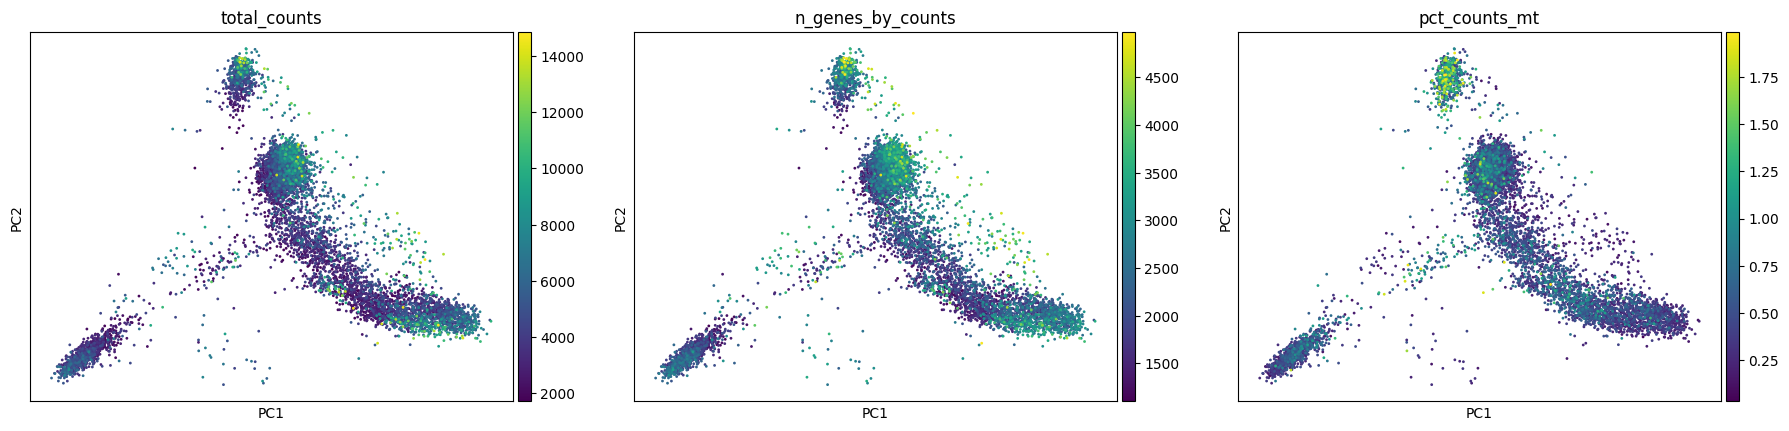

In [ ]:
sc.pl.pca(
    adata,
    color=["total_counts", "n_genes_by_counts", "pct_counts_mt"],
    ncols=3
)

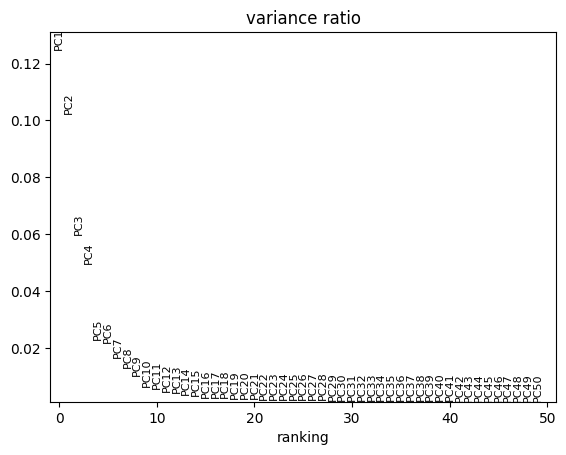

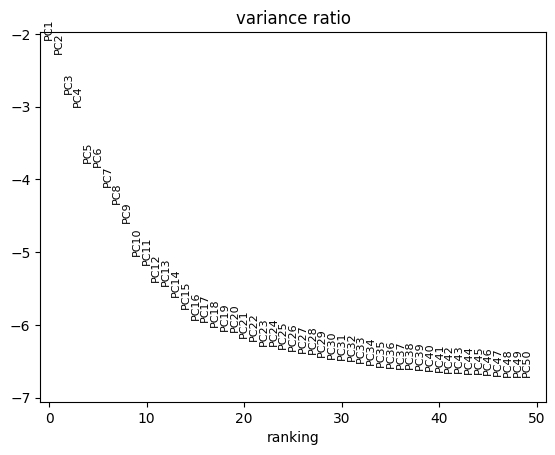

In [ ]:
sc.pl.pca_variance_ratio(adata, n_pcs=50)
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True) #в логарифмической шкале

3. Постройте граф соседства клеток и вычислите UMAP.

Для построения графа соседства выбрем первые 20 главных компонент PCA. На графике объяснённой дисперсии видно, что наибольший вклад в вариацию данных вносят первые компоненты, а после 15–20 компонент вклад каждой последующей становится относительно небольшим

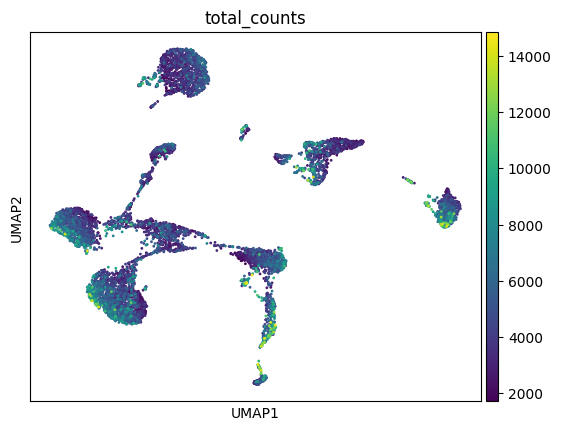

In [ ]:
sc.pp.neighbors(
    adata,
    n_neighbors=15,
    n_pcs=20,
    random_state=42
)

sc.tl.umap(
    adata,
    min_dist=0.3,
    random_state=42
)

sc.pl.umap(adata, color="total_counts")

4. Выполните кластеризацию Leiden с двумя различными значениями `resolution`, например 0.3 и 1.0.

In [ ]:
sc.tl.leiden(
    adata,
    resolution=0.3,
    key_added="leiden_0.3",
    random_state=42
)

sc.tl.leiden(
    adata,
    resolution=1.0,
    key_added="leiden_1.0",
    random_state=42
)

print("resolution=0.3:", adata.obs["leiden_0.3"].nunique(), "кластеров")
print("resolution=1.0:", adata.obs["leiden_1.0"].nunique(), "кластеров")

/tmp/ipykernel_443/4111004487.py:1: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(
/tmp/ipykernel_443/4111004487.py:8: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(


resolution=0.3: 12 кластеров
resolution=1.0: 20 кластеров


5. Постройте два UMAP с результатами кластеризации.

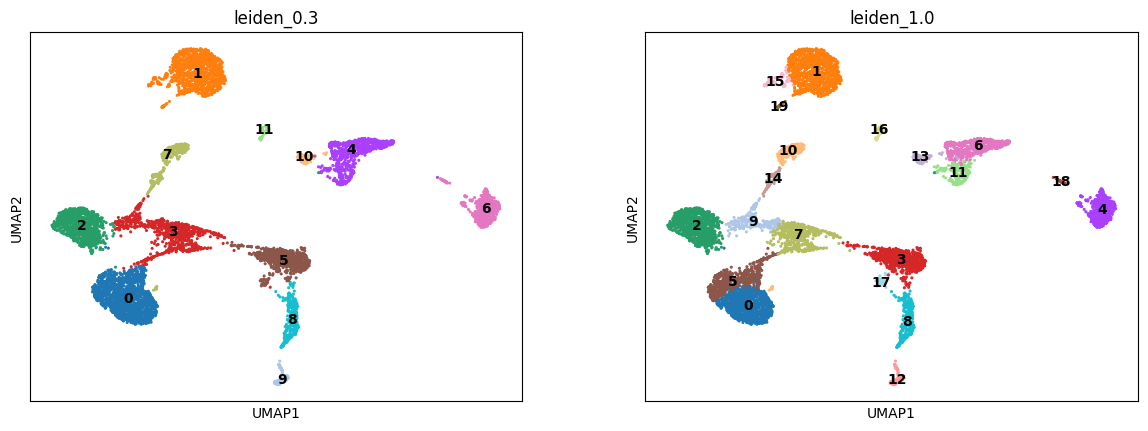

In [ ]:
sc.pl.umap(
    adata,
    color=["leiden_0.3", "leiden_1.0"],
    ncols=2,
    legend_loc="on data",
    size=20
)

6. Сравните количество и размеры получившихся кластеров.

При `resolution=0.3` было получено 12 кластеров, а при `resolution=1.0` - 20 кластеров.

При увеличении resolution некоторые крупные кластеры разделились на более мелкие, что хорошо видно на UMAP.Размеры кластеров неодинаковы: присутствуют как крупные группы, содержащие много клеточных ядер, так и небольшие обособленные популяции

Для дальнейшей аннотации можно предварительно выбрать `resolution=0.3`, поскольку оно даёт меньше кластеров, которые потенциально проще интерпретировать биологически

**Вопросы:**
- Как изменение `resolution` влияет на число кластеров?

    При увеличении resolution алгоритм Leiden обычно выделяет больше кластеров, поскольку разделяет клетки на более мелкие группы
- Какие кластеры разделились при увеличении разрешения?

    По UMAP видно, что некоторые крупные кластеры разделились на несколько более мелких (например область кластера 1 при увеличении разрешения разделилась на группы 1, 15 и 19)
- Обязательно ли каждый получившийся кластер соответствует отдельному типу клеток?

    Нет, не обязательно. Один тип клеток может разделяться на несколько кластеров из-за различий в функциональном состоянии, стадии развития или уровне экспрессии отдельных генов + на кластеризацию могут влиять технические факторы. Поэтому для определения клеточных типов необходимо дополнительно анализировать маркерные гены


### Задание 4. Ручная аннотация клеток

1. Найдите маркерные гены кластеров с помощью `sc.tl.rank_genes_groups()`.

In [ ]:
sc.tl.rank_genes_groups(
    adata,
    groupby="leiden_0.3",
    method="wilcoxon",
    reference="rest",
    use_raw=False,
    layer=None,
    tie_correct=True,
    corr_method="benjamini-hochberg",
    pts=True,
    key_added="wilcoxon"
)

2. Для каждого кластера рассмотрите наиболее высокоранжированные гены, их экспрессию и долю экспрессирующих клеток.

In [ ]:
clusters = list(adata.obs["leiden_0.3"].cat.categories)

for cluster in clusters:
    markers = sc.get.rank_genes_groups_df(
        adata,
        group=cluster,
        key="wilcoxon",
        gene_symbols="feature_name")

    print(f"\nКластер {cluster}")

    display(
        markers[
            ["feature_name", "logfoldchanges",
             "pvals_adj", "pct_nz_group",
             "pct_nz_reference"]
        ].head(10).round(3))


Кластер 0


,feature_name,logfoldchanges,pvals_adj,pct_nz_group,pct_nz_reference
0,DAAM2,3.975,0.0,0.870,0.190
1,LRIG1,3.570,0.0,0.978,0.455
2,OBI1-AS1,4.169,0.0,0.961,0.238
3,ARHGEF4,3.779,0.0,0.842,0.197
4,CD44,4.252,0.0,0.739,0.116
5,DPP10,4.302,0.0,0.988,0.574
6,GFAP,2.549,0.0,0.991,0.778
7,LIFR,3.180,0.0,0.961,0.474
8,ADCY8,3.736,0.0,0.768,0.150
9,RFX4,3.328,0.0,0.955,0.405



Кластер 1


,feature_name,logfoldchanges,pvals_adj,pct_nz_group,pct_nz_reference
0,ADAM28,9.095,0.0,0.953,0.019
1,SLC11A1,8.105,0.0,0.957,0.037
2,APBB1IP,7.959,0.0,0.911,0.025
3,CSF3R,8.479,0.0,0.818,0.008
4,SYK,7.858,0.0,0.819,0.014
5,LRMDA,7.888,0.0,0.972,0.077
6,TLR2,7.399,0.0,0.821,0.023
7,RUNX1,6.867,0.0,0.909,0.052
8,LNCAROD,8.304,0.0,0.775,0.013
9,MS4A7,7.415,0.0,0.803,0.019



Кластер 2


,feature_name,logfoldchanges,pvals_adj,pct_nz_group,pct_nz_reference
0,ADGRV1,4.246,0.0,0.994,0.521
1,TSHR,3.829,0.0,0.795,0.173
2,MOXD1,3.700,0.0,0.703,0.118
3,LRRC3B,3.593,0.0,0.803,0.187
4,PDGFRB,3.902,0.0,0.544,0.059
5,TNC,3.536,0.0,0.969,0.339
6,PREX2,3.180,0.0,0.893,0.356
7,SLC1A2,3.000,0.0,0.992,0.649
8,MAST4,2.894,0.0,0.950,0.448
9,PDGFD,3.844,0.0,0.484,0.053


... (14 outputs left out)


Кластер 10


,feature_name,logfoldchanges,pvals_adj,pct_nz_group,pct_nz_reference
0,LHX6,6.240,0.0,0.443,0.010
1,EPHA3,4.903,0.0,0.896,0.094
2,NYAP2,4.491,0.0,0.708,0.061
3,KCNC2,4.906,0.0,0.745,0.071
4,CUX2,4.814,0.0,0.792,0.092
5,NXPH1,6.177,0.0,0.991,0.171
6,ZNF536,4.709,0.0,0.896,0.125
7,GRIP2,4.157,0.0,0.604,0.057
8,CNTNAP4,4.527,0.0,0.726,0.092
9,SRRM4,4.466,0.0,0.877,0.149



Кластер 11


,feature_name,logfoldchanges,pvals_adj,pct_nz_group,pct_nz_reference
0,TBX3,11.015,0.0,0.574,0.001
1,EMCN,10.534,0.0,0.459,0.001
2,CD34,9.251,0.0,0.492,0.001
3,MECOM,9.084,0.0,0.689,0.005
4,ITGA1,8.530,0.0,0.820,0.010
5,ADGRF5,8.637,0.0,0.574,0.003
6,EBF1,8.662,0.0,0.754,0.008
7,BTNL9,8.438,0.0,0.590,0.004
8,SLC38A11,10.067,0.0,0.443,0.001
9,ESAM,8.838,0.0,0.459,0.002


3. Найдите в литературе или специализированных базах известные маркеры предполагаемых клеточных типов.

Среди кластеров обнаружены характерные маркеры олигодендроцитов (MOBP, OPALIN), их предшественников (PDGFRA), созревающих олигодендроцитов (GPR17, ENPP6), астроцитарной глии (GFAP), тормозных нейронов (ADARB2, LHX6), эндотелиальных клеток (EMCN, CD34) и клеток с двигательными ресничками (DNAAF1, DNAH5)

Для некоторых кластеров маркеры менее однозначны, поэтому их предполагаемая идентичность требует дополнительной проверки экспрессии других генов


4. Постройте `dotplot` и UMAP с экспрессией выбранных маркеров.

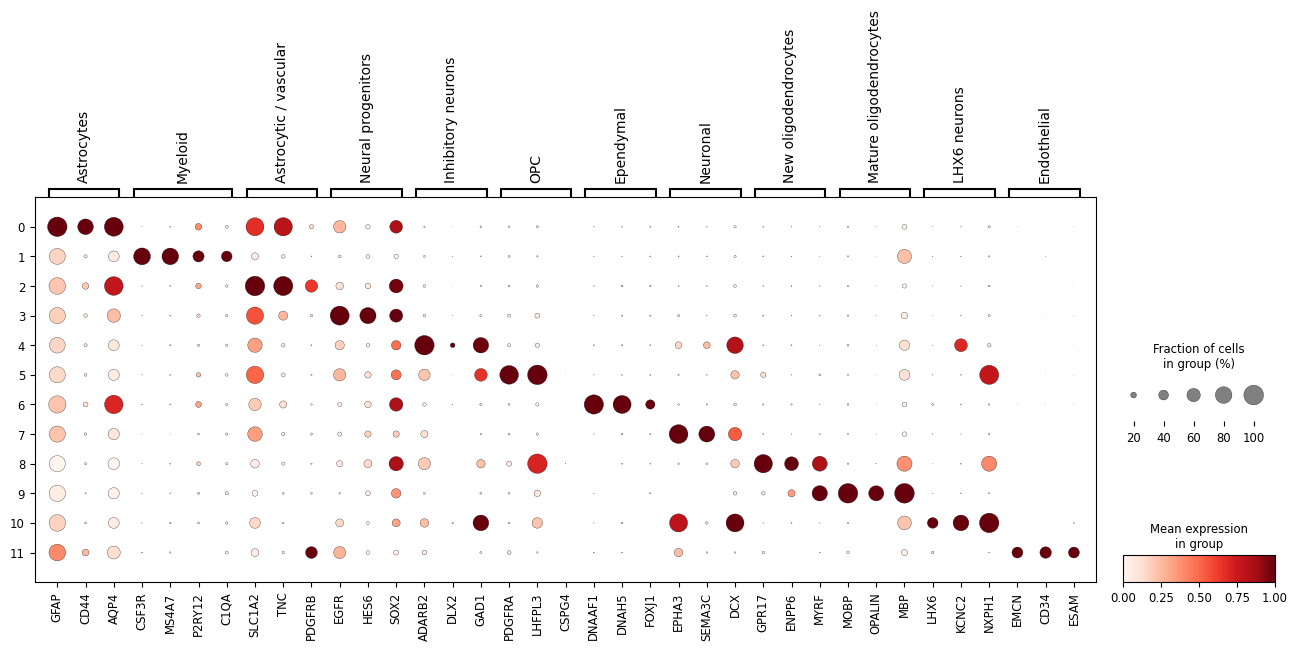

In [ ]:
MARKERS = {"Astrocytes": ["GFAP", "CD44", "AQP4"],
    "Myeloid": ["CSF3R", "MS4A7", "P2RY12", "C1QA"],
    "Astrocytic / vascular": ["SLC1A2", "TNC", "PDGFRB"],
    "Neural progenitors": ["EGFR", "HES6", "SOX2"],
    "Inhibitory neurons": ["ADARB2", "DLX2", "GAD1"],
    "OPC": ["PDGFRA", "LHFPL3", "CSPG4"],
    "Ependymal": ["DNAAF1", "DNAH5", "FOXJ1"],
    "Neuronal": ["EPHA3", "SEMA3C", "DCX"],
    "New oligodendrocytes": ["GPR17", "ENPP6", "MYRF"],
    "Mature oligodendrocytes": ["MOBP", "OPALIN", "MBP"],
    "LHX6 neurons": ["LHX6", "KCNC2", "NXPH1"],
    "Endothelial": ["EMCN", "CD34", "ESAM"]}

markers_present = {
    k: [g for g in genes if g in adata.var["feature_name"].values]
    for k, genes in MARKERS.items()}

markers_present = {
    k: v for k, v in markers_present.items() if v}

sc.pl.dotplot(
    adata,
    var_names=markers_present,
    groupby="leiden_0.3",
    gene_symbols="feature_name",
    standard_scale="var",
    use_raw=False,
    figsize=(16, 5))

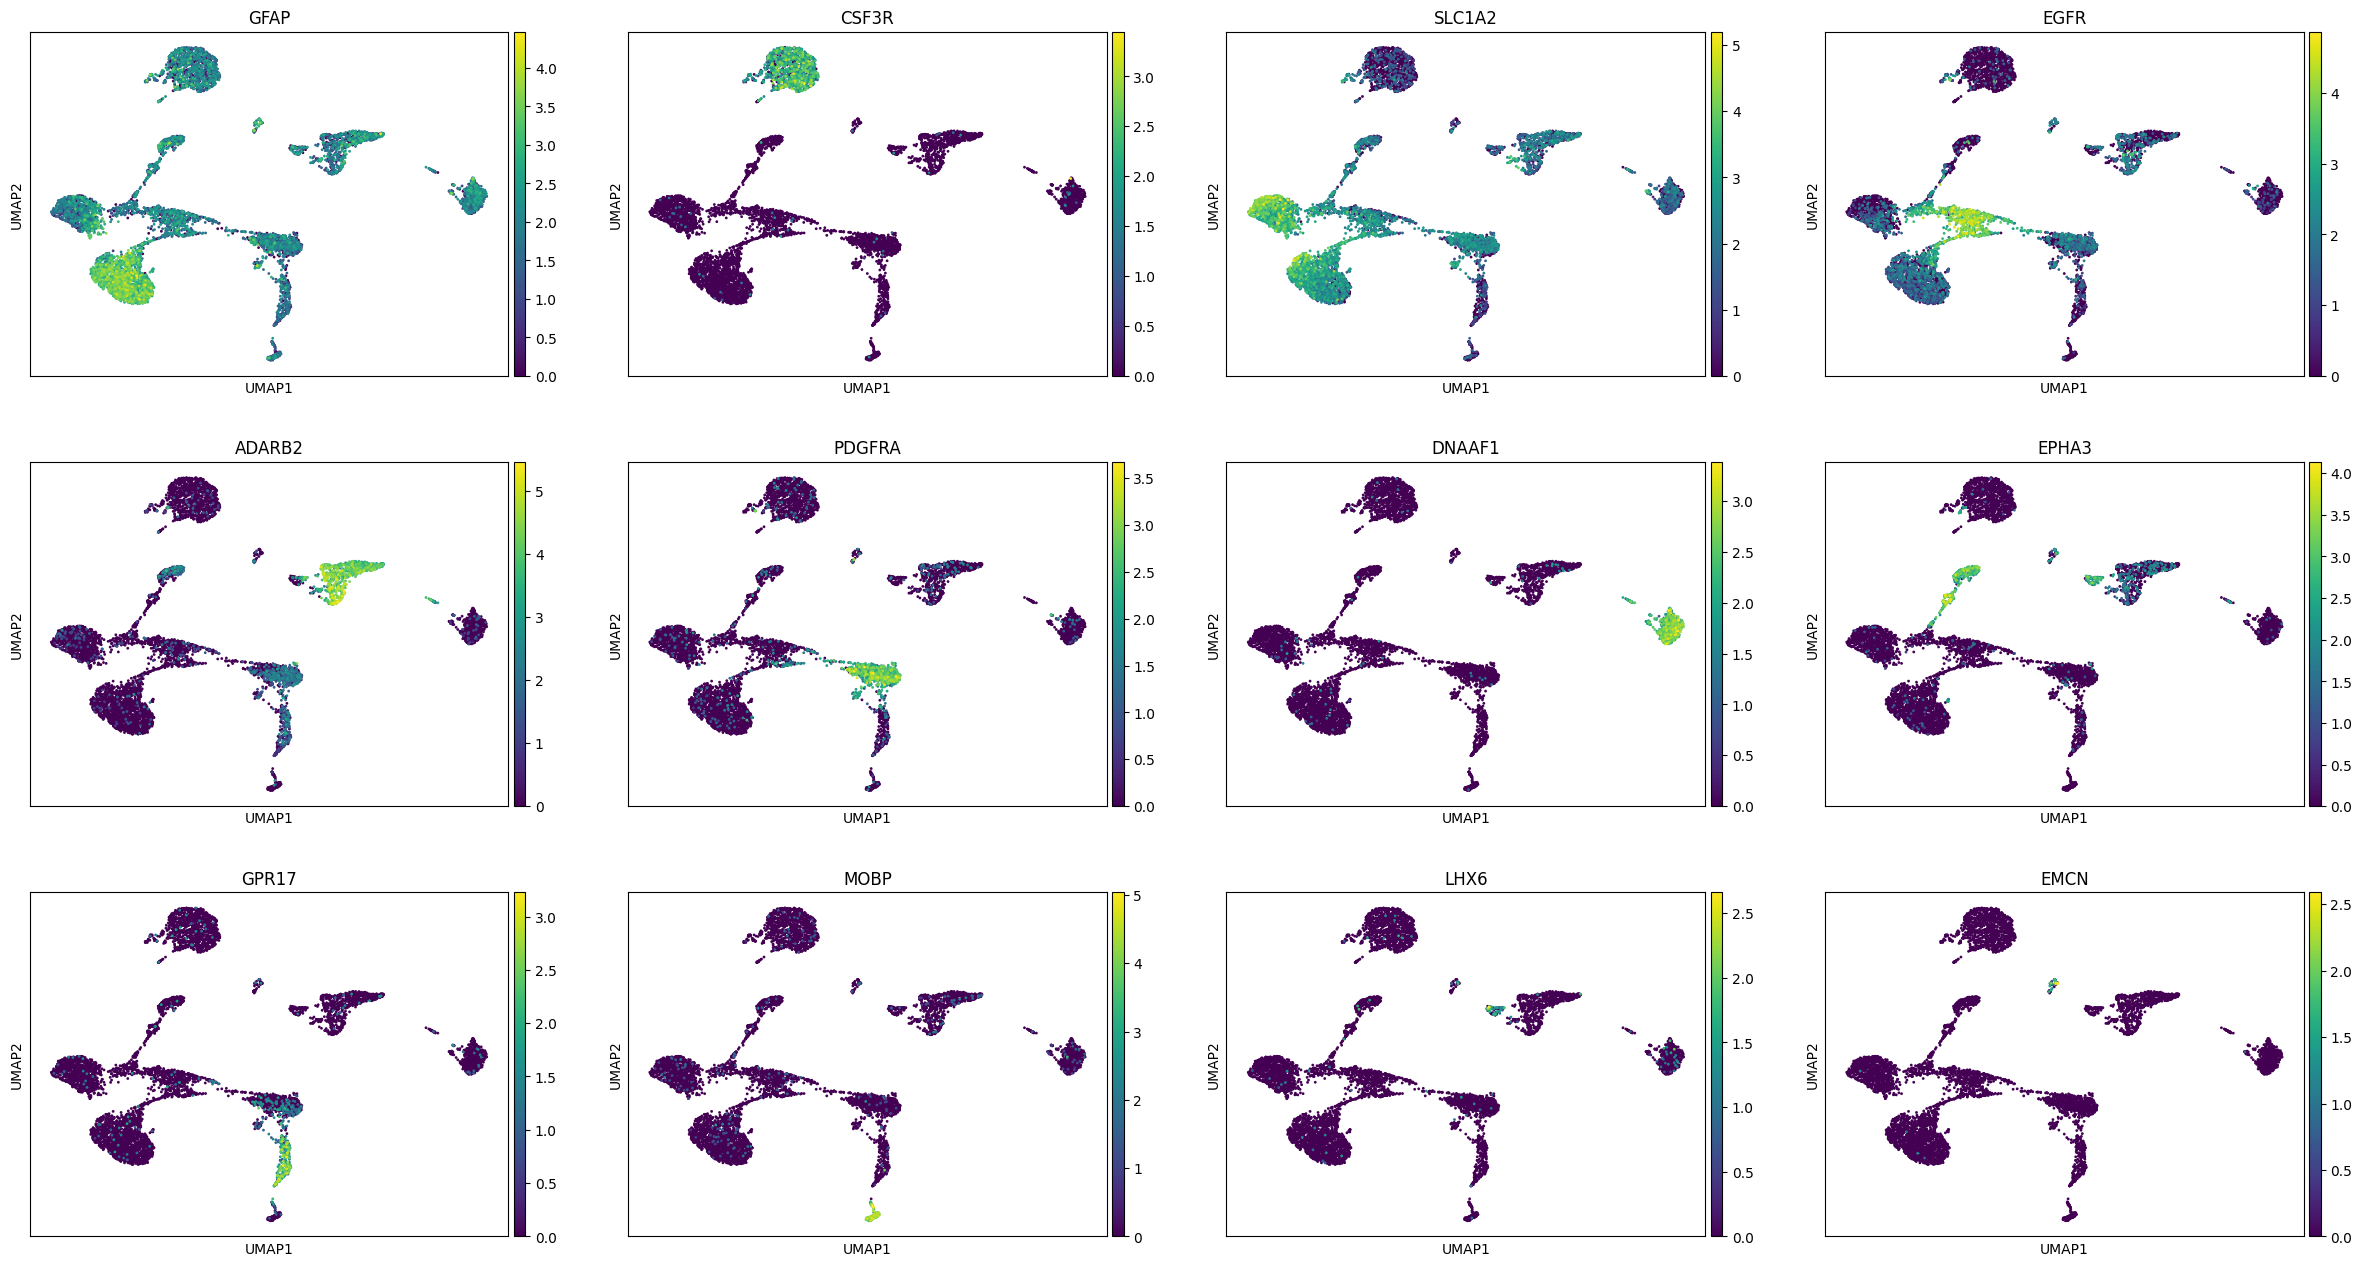

In [ ]:
genes_umap = ["GFAP", "CSF3R", "SLC1A2", "EGFR",
    "ADARB2", "PDGFRA", "DNAAF1", "EPHA3",
    "GPR17", "MOBP", "LHX6", "EMCN"]

sc.pl.umap(
    adata,
    color=genes_umap,
    gene_symbols="feature_name",
    use_raw=False,
    ncols=4)

5. Присвойте каждому кластеру предполагаемый клеточный тип и сохраните результаты в `adata.obs["manual_cell_type"]`.

In [ ]:
manual_annotations = {"0": "Astrocytes (GFAP+)",
    "1": "Myeloid cells",
    "2": "Astrocytes (SLC1A2+)",
    "3": "Immature neural/glial cells",
    "4": "Inhibitory neurons (ADARB2+)",
    "5": "OPC",
    "6": "Multiciliated / ependymal-like cells",
    "7": "Immature neurons",
    "8": "Differentiating oligodendrocytes",
    "9": "Mature oligodendrocytes",
    "10": "Inhibitory neurons (LHX6+)",
    "11": "Endothelial cells"}

adata.obs["manual_cell_type"] = (
    adata.obs["leiden_0.3"]
    .astype(str)
    .map(manual_annotations)
    .astype("category"))

print(adata.obs[["leiden_0.3", "manual_cell_type"]].head())

                   leiden_0.3                      manual_cell_type
AAACCCAAGGTCTTTG-1          2                  Astrocytes (SLC1A2+)
AAACCCACACTCAGAT-1          0                    Astrocytes (GFAP+)
AAACCCAGTACCAGAG-1          6  Multiciliated / ependymal-like cells
AAACCCAGTGCGGTAA-1          3           Immature neural/glial cells
AAACCCAGTTCGGCGT-1          5                                   OPC


| Кластер | Предполагаемый клеточный тип | Маркерные гены | Обоснование |
|---|---|---|---|
| 0 | Astrocytes (GFAP+) | GFAP, CD44, DAAM2 | Высокая экспрессия GFAP и CD44, характерных для астроцитарной глии |
| 1 | Myeloid cells | CSF3R, TLR2, MS4A7 | Гены связаны с клетками миелоидной иммунной системы  |
| 2 | Astrocytes (SLC1A2+) | SLC1A2, TNC, ADGRV1 | Высокая экспрессия SLC1A2 и AQP4 поддерживает астроцитарную идентичность (наличие PDGFRB требует дополнительной проверки) |
| 3 | Immature neural/glial cells | EGFR, HES6, SOX2 | Экспрессия генов EGFR, HES6 и SOX2 может указывать на незрелое или прогениторное состояние клеток |
| 4 | Inhibitory neurons (ADARB2+) | DLX6-AS1, ADARB2, MYT1L | Выражены гены, связанные с развитием тормозных интернейронов |
| 5 | OPC | PDGFRA, LHFPL3, PCDH15 | Высокая и специфичная экспрессия PDGFRA и LHFPL3 характерна для предшественников олигодендроцитов |
| 6 | Multiciliated / ependymal-like cells | DNAAF1, CFAP157, DNAH5 | Высокая экспрессия генов, участвующих в формировании и движении ресничек |
| 7 | Immature neurons | EPHA3, SEMA3C, NRG1 | Гены связаны с развитием нейронов и направлением роста их отростков |
| 8 | Differentiating oligodendrocytes | GPR17, ENPP6, MYRF | Маркеры характерны для созревающих олигодендроцитов на промежуточных стадиях дифференцировки|
| 9 | Mature oligodendrocytes | OPALIN, MOBP, MAL | Высокая экспрессия генов, связанных с формированием и поддержанием миелиновой оболочки |
| 10 | Inhibitory neurons (LHX6+) | LHX6, KCNC2, NXPH1 | Экспрессия LHX6 и других нейрональных маркеров поддерживает принадлежность к популяции тормозных интернейронов |
| 11 | Endothelial cells | EMCN, CD34, ESAM | Совместная экспрессия характерных маркеров эндотелия кровеносных сосудов |

Предположительно выделены астроциты, миелоидные клетки, нейрональные популяции, предшественники и зрелые олигодендроциты, эндотелиальные и реснитчатые клетки

Особенно хорошо прослеживаются различные стадии развития олигодендроцитов: от предшественников (кластер 5) до дифференцирующихся (кластер 8) и зрелых миелинизирующих клеток (кластер 9)

Для кластеров 2, 3 и 7 использовались предварительные обозначения, тк их маркеры не позволяет уверенно определить точный клеточный подтип


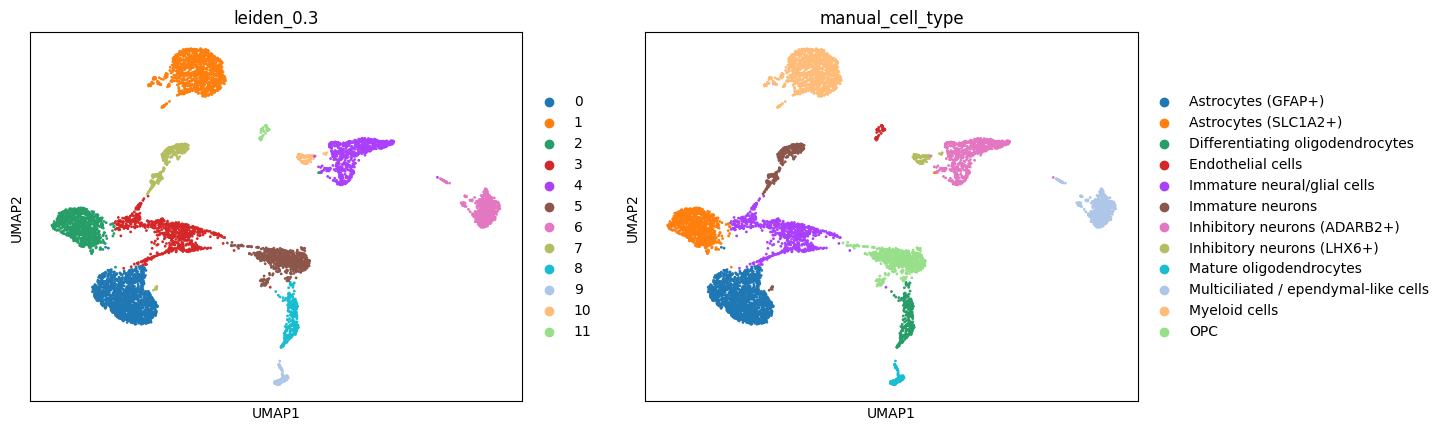

In [ ]:
sc.pl.umap(
    adata,
    color=["leiden_0.3", "manual_cell_type"],
    ncols=2,
    legend_loc="right margin")

### Задание 5. Автоматическая аннотация

1. Найдите инструмент автоматической аннотации клеточных типов или используйте `CellTypist`.

In [ ]:
%pip install -q celltypist

2. Выберите подходящую референсную модель для вашего датасета.

In [ ]:
import celltypist
celltypist.models.models_description()

/usr/local/lib/python3.13/dist-packages/celltypist/classifier.py:11: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  from scanpy import __version__ as scv


,model,description
0,Immune_All_Low.pkl,immune sub-populations combined from 20 tissue...
1,Immune_All_High.pkl,immune populations combined from 20 tissues of...
2,Adult_COVID19_PBMC.pkl,peripheral blood mononuclear cell types from C...
3,Adult_CynomolgusMacaque_Hippocampus.pkl,cell types from the hippocampus of adult cynom...
4,Adult_Human_MTG.pkl,cell types and subtypes (10x-based) from the a...
...,...,...
56,Nuclei_Lung_Airway.pkl,cell populations from snRNA-seq of five locati...
57,PaediatricAdult_COVID19_Airway.pkl,cell types in the airway of paediatric and adu...
58,PaediatricAdult_COVID19_PBMC.pkl,peripheral blood mononuclear cell types of pae...
59,Pan_Fetal_Human.pkl,stromal and immune populations from the human ...


In [ ]:
models_df = celltypist.models.models_description()

models_df[
    models_df["model"].str.contains(
        "Brain|MTG|Hippocampus",
        case=False)]

,model,description
3,Adult_CynomolgusMacaque_Hippocampus.pkl,cell types from the hippocampus of adult cynom...
4,Adult_Human_MTG.pkl,cell types and subtypes (10x-based) from the a...
11,Adult_Pig_Hippocampus.pkl,cell types from the adult pig hippocampus
12,Adult_RhesusMacaque_Hippocampus.pkl,cell types from the hippocampus of adult rhesu...
23,Developing_Human_Brain.pkl,cell types from the first-trimester developing...
25,Developing_Human_Hippocampus.pkl,cell types from the developing human hippocampus
28,Developing_Mouse_Brain.pkl,cell types from the embryonic mouse brain betw...
29,Developing_Mouse_Hippocampus.pkl,cell types from the mouse hippocampus at postn...
39,Human_AdultAged_Hippocampus.pkl,cell types from the hippocampus of adult and a...
45,Human_Longitudinal_Hippocampus.pkl,cell types from the adult human anterior and p...


Для автоматической аннотации клеточных типов выберем инструмент CellTypist с предварительно обученной моделью Developing_Human_Brain.pkl. Данная модель предназначена для анализа клеток развивающегося головного мозга человека, однако модель обучена на данных первого триместра развития. Это различие может снижать точность автоматической аннотации

In [ ]:
celltypist.models.download_models(
    model="Developing_Human_Brain.pkl")

3. Выполните автоматическую аннотацию клеток.

In [ ]:
adata_ct = adata.copy()

adata_ct.var_names = adata_ct.var["feature_name"].astype(str)
adata_ct.var_names_make_unique()

print(adata_ct)

AnnData object with n_obs × n_vars = 7415 × 18515
    obs: 'nCount_RNA', 'nFeature_RNA', 'donor_id', 'percent.mt', 'nuclear_fraction', 'author_cell_type', 'assay_ontology_term_id', 'disease_ontology_term_id', 'suspension_type', 'tissue_ontology_term_id', 'cell_type_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'development_stage_ontology_term_id', 'sex_ontology_term_id', 'tissue_type', 'is_primary_data', 'cell_type', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes', 'leiden_0.3', 'leiden_1.0', 'manual_cell_type'
    var: 'vst.mean', 'vst.variance', 'vst.variance.expected', 'vst.variance.standardized', 'vst.variable', 'feature_name', 'feature_reference', 'feature_biotype', 'feature_length', 'feature_type', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean

In [ ]:
predictions = celltypist.annotate(
    adata_ct,
    model="Developing_Human_Brain.pkl",
    majority_voting=False
)

In [ ]:
adata.obs["celltypist_cell_type"] = (
    predictions.predicted_labels["predicted_labels"]
    .reindex(adata.obs_names)
)

4. Постройте UMAP с результатами автоматической аннотации.

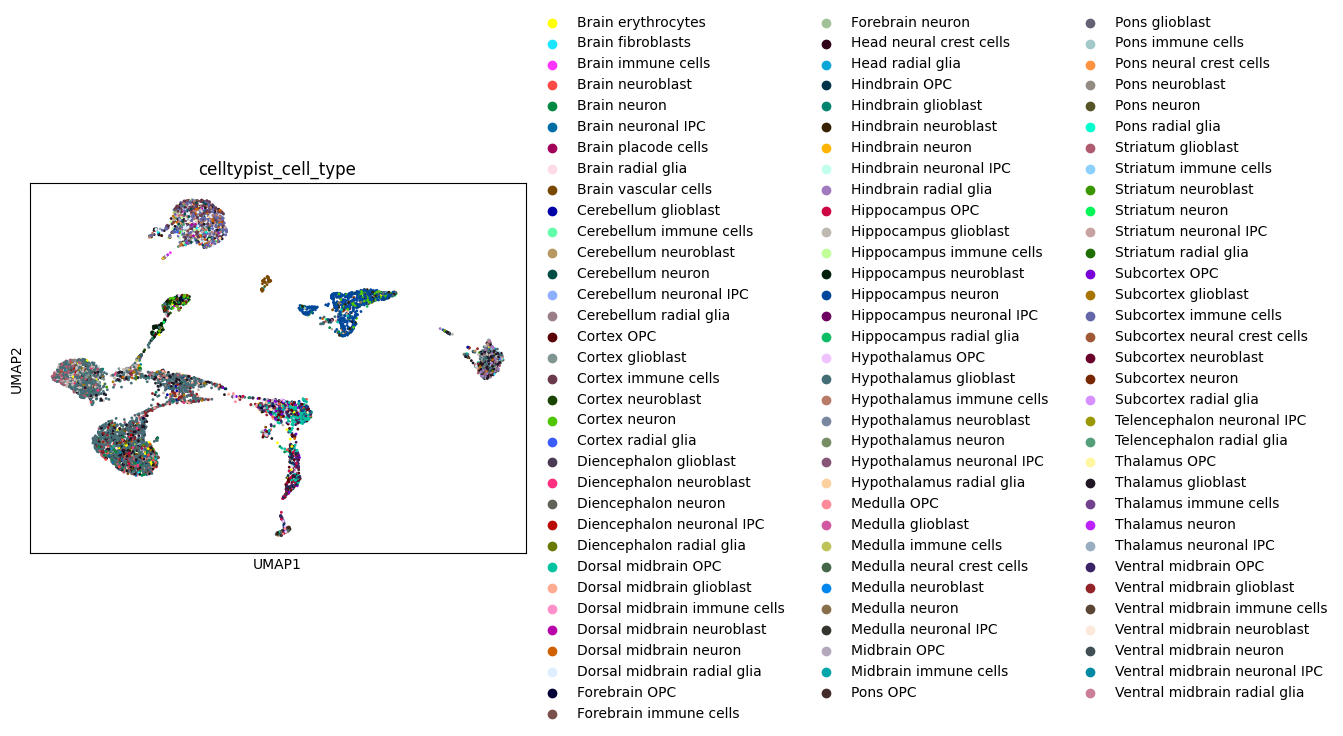

In [ ]:
sc.pl.umap(
    adata,
    color="celltypist_cell_type",
    legend_loc="right margin"
)

5. Сравните результаты с вашей ручной аннотацией.

Посмотрим таблицу сопряжённости по кластерам Leiden (сколько клеточных ядер каждого кластера CellTypist отнёс к каждому типу)

In [ ]:
import pandas as pd

cluster_comparison = pd.crosstab(
    adata.obs["leiden_0.3"],
    adata.obs["celltypist_cell_type"]
)

display(cluster_comparison)

celltypist_cell_type,Brain erythrocytes,Brain fibroblasts,Brain immune cells,Brain neuroblast,Brain neuron,Brain neuronal IPC,Brain placode cells,Brain radial glia,Brain vascular cells,Cerebellum glioblast,...,Thalamus immune cells,Thalamus neuron,Thalamus neuronal IPC,Ventral midbrain OPC,Ventral midbrain glioblast,Ventral midbrain immune cells,Ventral midbrain neuroblast,Ventral midbrain neuron,Ventral midbrain neuronal IPC,Ventral midbrain radial glia
leiden_0.3,,,,,,,,,,,,,,,,,,,,,
0,25,5,0,64,75,20,4,22,15,0,...,0,0,2,0,58,1,1,2,7,0
1,1,3,2,1,0,3,1,0,1,0,...,3,2,6,0,1,1,0,1,0,3
2,9,0,0,4,6,0,1,1,6,0,...,0,0,0,0,7,1,0,1,4,0
3,6,0,0,1,3,1,0,0,0,8,...,0,0,3,1,77,1,0,1,1,0
4,5,0,0,1,5,0,0,0,2,0,...,0,0,2,1,0,1,0,0,0,0
5,5,2,0,27,14,0,0,0,1,0,...,0,0,0,126,19,1,0,0,0,0
6,2,1,0,1,0,2,0,1,0,2,...,1,0,14,0,12,0,0,0,0,18
7,13,0,0,1,23,0,0,1,1,0,...,0,1,0,0,0,1,0,0,0,0
8,5,0,0,2,3,0,0,0,0,0,...,0,0,0,69,2,0,0,0,0,0


Теперь посмотрим таблицу сопряжённости с ручной аннотацией

In [ ]:
comparison = pd.crosstab(
    adata.obs["manual_cell_type"],
    adata.obs["celltypist_cell_type"]
)

display(comparison)

celltypist_cell_type,Brain erythrocytes,Brain fibroblasts,Brain immune cells,Brain neuroblast,Brain neuron,Brain neuronal IPC,Brain placode cells,Brain radial glia,Brain vascular cells,Cerebellum glioblast,...,Thalamus immune cells,Thalamus neuron,Thalamus neuronal IPC,Ventral midbrain OPC,Ventral midbrain glioblast,Ventral midbrain immune cells,Ventral midbrain neuroblast,Ventral midbrain neuron,Ventral midbrain neuronal IPC,Ventral midbrain radial glia
manual_cell_type,,,,,,,,,,,,,,,,,,,,,
Astrocytes (GFAP+),25,5,0,64,75,20,4,22,15,0,...,0,0,2,0,58,1,1,2,7,0
Astrocytes (SLC1A2+),9,0,0,4,6,0,1,1,6,0,...,0,0,0,0,7,1,0,1,4,0
Differentiating oligodendrocytes,5,0,0,2,3,0,0,0,0,0,...,0,0,0,69,2,0,0,0,0,0
Endothelial cells,0,2,0,0,0,0,0,0,57,0,...,0,0,0,0,0,0,0,0,0,0
Immature neural/glial cells,6,0,0,1,3,1,0,0,0,8,...,0,0,3,1,77,1,0,1,1,0
Immature neurons,13,0,0,1,23,0,0,1,1,0,...,0,1,0,0,0,1,0,0,0,0
Inhibitory neurons (ADARB2+),5,0,0,1,5,0,0,0,2,0,...,0,0,2,1,0,1,0,0,0,0
Inhibitory neurons (LHX6+),0,0,0,0,2,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,1
Mature oligodendrocytes,0,0,0,1,0,0,0,1,0,1,...,0,0,0,12,0,0,0,0,0,0


**Вопросы:**
- Для каких кластеров ручная и автоматическая аннотации совпали?

    Наиболее явное совпадение наблюдается для кластера 11: при ручной аннотации он был определён как эндотелиальные клетки, а CellTypist отнёс 57 из 61 ядра к Brain vascular cells. Частичное соответствие также наблюдается для кластеров 5 и 8, которые вручную были определены как предшественники и дифференцирующиеся олигодендроциты (CellTypist часть их ядер относит к категории OPC)
- Где наблюдаются расхождения?

    Заметные расхождения наблюдаются для астроцитарных и некоторых других популяций. Например в кластере 0, определённом вручную как астроциты, CellTypist предсказывает несколько разных типов клеток, включая нейроны и нейробласты. Для кластера 6, определённого как эпендимоподобные клетки, также наблюдается неоднородность автоматических предсказаний (вместо одного клеточного типа модель присваивает ядрам разные метки)
- С чем они могут быть связаны?

    Расхождения могут быть связаны с особенностями обучающего датасета CellTypist (модель Developing_Human_Brain обучалась на клетках мозга плода первого триместра, а наши данные получены из мозга ребёнка в возрасте 14 дней после рождения). Дополнительными причинами могут быть сходство профилей экспрессии родственных клеточных типов и различия в стадиях их развития
- Какую аннотацию вы считаете более обоснованной и почему?

    Для данного датасета я считаю ручную аннотацию более обоснованной,тк она опирается на несколько известных маркерных генов, результаты дифференциальной экспрессии, долю экспрессирующих ядер и визуализации dotplot и UMAP (автоматическая аннотация полезна как дополнительный независимый подход, позволяющий проверить некоторые предположения и выявить неоднозначные популяции. Для окончательной идентификации я буду опираться на нескольких источников информации)

Можно попробовать другую модель CellTypist - Adult_Human_MTG.pkl (Височная кора взрослого человека). Модель анатомически ближе к нашей энторинальной коре, но возраст образцов отличается, поэтому это не гарантирует более точную аннотацию

In [37]:
celltypist.models.download_models(
    model="Adult_Human_MTG.pkl"
)

In [38]:
predictions_mtg = celltypist.annotate(
    adata_ct,
    model="Adult_Human_MTG.pkl",
    majority_voting=False
)

adata.obs["celltypist_mtg"] = (
    predictions_mtg.predicted_labels["predicted_labels"]
    .reindex(adata.obs_names)
)

print("Количество предсказанных типов:",
      adata.obs["celltypist_mtg"].nunique())

print(adata.obs["celltypist_mtg"].value_counts())

Количество предсказанных типов: 92
celltypist_mtg
Astro_3        1695
OPC_2          1499
Micro-PVM_2    1235
L2/3 IT_6       321
OPC_1           285
               ... 
L6b_4             1
Sst_22            1
Sncg_8            1
Pvalb_9           1
Sst_7             1
Name: count, Length: 92, dtype: int64


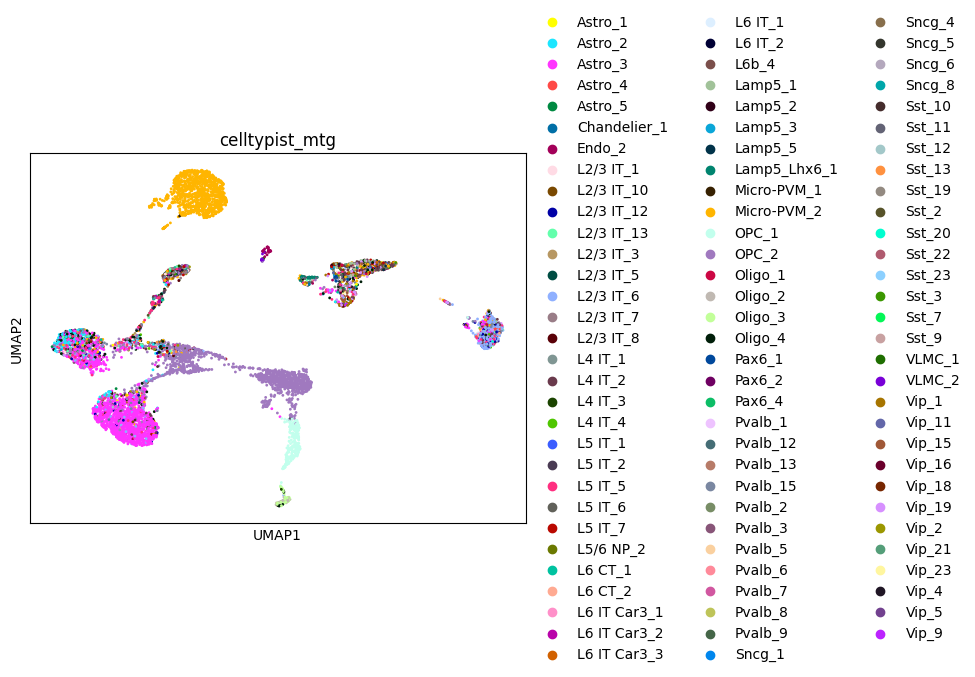

In [39]:
sc.pl.umap(
    adata,
    color="celltypist_mtg",
    legend_loc="right margin"
)

In [40]:
comparison_mtg = pd.crosstab(
    adata.obs["manual_cell_type"],
    adata.obs["celltypist_mtg"]
)

display(comparison_mtg)

celltypist_mtg,Astro_1,Astro_2,Astro_3,Astro_4,Astro_5,Chandelier_1,Endo_2,L2/3 IT_1,L2/3 IT_10,L2/3 IT_12,...,Vip_15,Vip_16,Vip_18,Vip_19,Vip_2,Vip_21,Vip_23,Vip_4,Vip_5,Vip_9
manual_cell_type,,,,,,,,,,,,,,,,,,,,,
Astrocytes (GFAP+),10,18,1248,0,5,0,2,0,3,11,...,0,0,0,1,3,0,0,0,0,0
Astrocytes (SLC1A2+),4,130,336,1,16,0,0,6,2,10,...,0,0,1,7,2,0,0,0,0,3
Differentiating oligodendrocytes,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Endothelial cells,0,0,0,0,0,0,39,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Immature neural/glial cells,1,21,26,0,4,0,0,1,4,5,...,1,0,0,4,8,0,1,0,3,0
Immature neurons,2,3,9,0,0,0,0,6,0,1,...,0,0,0,2,3,0,0,10,0,0
Inhibitory neurons (ADARB2+),4,2,22,0,0,0,1,10,5,1,...,25,3,1,46,5,5,8,2,2,6
Inhibitory neurons (LHX6+),0,0,0,0,0,1,1,1,1,1,...,0,0,0,2,0,0,0,0,0,0
Mature oligodendrocytes,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


Дополнительно для каждого из моих 12 кластеров определим три наиболее распространённые автоматические метки и рассчитаем доли ядер, получивших соответствующие предсказания

In [41]:
cluster_mtg = pd.crosstab(
    adata.obs["leiden_0.3"],
    adata.obs["celltypist_mtg"]
)

for cluster in cluster_mtg.index:
    print(f"\nКластер {cluster}")

    counts = cluster_mtg.loc[cluster]
    top3 = counts.sort_values(ascending=False).head(3)

    print(top3)
    print("Доли, %:")
    print((top3 / counts.sum() * 100).round(1))


Кластер 0
celltypist_mtg
Astro_3      1248
OPC_2          48
L2/3 IT_6      38
Name: 0, dtype: int64
Доли, %:
celltypist_mtg
Astro_3      81.9
OPC_2         3.2
L2/3 IT_6     2.5
Name: 0, dtype: float64

Кластер 1
celltypist_mtg
Micro-PVM_2    1086
Micro-PVM_1       4
L5 IT_5           1
Name: 1, dtype: int64
Доли, %:
celltypist_mtg
Micro-PVM_2    99.5
Micro-PVM_1     0.4
L5 IT_5         0.1
Name: 1, dtype: float64

Кластер 2
celltypist_mtg
Astro_3    336
Astro_2    130
Oligo_4     95
Name: 2, dtype: int64
Доли, %:
celltypist_mtg
Astro_3    36.2
Astro_2    14.0
Oligo_4    10.2
Name: 2, dtype: float64

Кластер 3
celltypist_mtg
OPC_2      546
L5 IT_5     43
Oligo_4     39
Name: 3, dtype: int64
Доли, %:
celltypist_mtg
OPC_2      66.7
L5 IT_5     5.3
Oligo_4     4.8
Name: 3, dtype: float64

Кластер 4
celltypist_mtg
L4 IT_2    92
Vip_1      58
Oligo_4    56
Name: 4, dtype: int64
Доли, %:
celltypist_mtg
L4 IT_2    12.1
Vip_1       7.7
Oligo_4     7.4
Name: 4, dtype: float64

Кластер 5
cellt

Наиболее выраженное соответствие ручной и автоматической аннотации наблюдается для кластеров 0, 1, 5, 8 и 9. Частичное соответствие наблюдается для кластеров 2, 3, 7, 10 и 11. Автоматическая модель в целом распознаёт родственные клеточные популяции, но иногда использует более детальные или отличающиеся названия. Наиболее заметные расхождения обнаружены для кластеров 4 и 6 (эпендимоподобные клетки кластера 6 преимущественно получили нейрональные метки, несмотря на выраженную экспрессию генов двигательных ресничек (DNAAF1, CFAP157, DNAH5))

По итогу для этого датасета ручную аннотацию я вижу более обоснованной

### Задание 6. Субкластеризация

Выберите один из полученных кластеров, который потенциально содержит несколько клеточных подтипов или функциональных состояний.

* Для субкластеризации берем кластер 4 (resolution=0.3), предположительно соответствующий тормозным нейронам, автоматическая аннотация CellTypist показала неоднородные предсказания внутри данной популяции


1. Создайте отдельный `AnnData`, содержащий только клетки выбранного кластера.

In [42]:
adata_sub = adata[
    adata.obs["leiden_0.3"] == "4"
].copy()

print(adata_sub)
print("Количество ядер:", adata_sub.n_obs)
print("Количество генов:", adata_sub.n_vars)

AnnData object with n_obs × n_vars = 758 × 18515
    obs: 'nCount_RNA', 'nFeature_RNA', 'donor_id', 'percent.mt', 'nuclear_fraction', 'author_cell_type', 'assay_ontology_term_id', 'disease_ontology_term_id', 'suspension_type', 'tissue_ontology_term_id', 'cell_type_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'development_stage_ontology_term_id', 'sex_ontology_term_id', 'tissue_type', 'is_primary_data', 'cell_type', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes', 'leiden_0.3', 'leiden_1.0', 'manual_cell_type', 'celltypist_cell_type', 'celltypist_mtg'
    var: 'vst.mean', 'vst.variance', 'vst.variance.expected', 'vst.variance.standardized', 'vst.variable', 'feature_name', 'feature_reference', 'feature_biotype', 'feature_length', 'feature_type', 'mt', 'n_cel

2. Повторите необходимые этапы анализа для этого подмножества: отбор HVG, PCA, построение графа соседства, UMAP и Leiden.

Число HVG: 2000


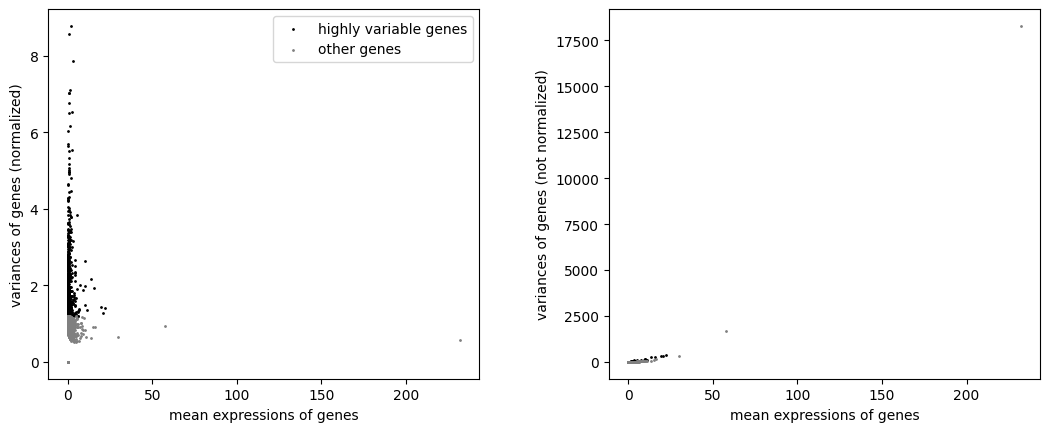

In [43]:
sc.pp.highly_variable_genes(
    adata_sub,
    layer="counts",
    flavor="seurat_v3",
    n_top_genes=2000)

print("Число HVG:", adata_sub.var["highly_variable"].sum())

sc.pl.highly_variable_genes(adata_sub)

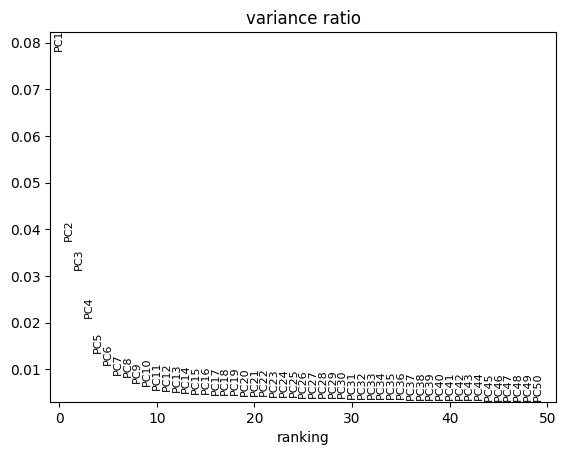

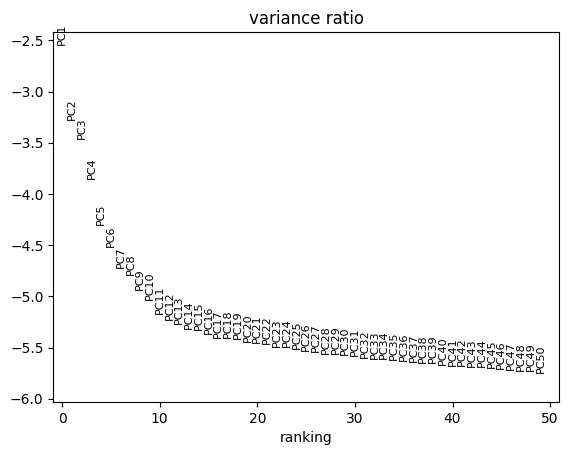

In [45]:
sc.tl.pca(
    adata_sub,
    n_comps=50,
    mask_var="highly_variable",
    random_state=42)

sc.pl.pca_variance_ratio(adata_sub, n_pcs=50)

sc.pl.pca_variance_ratio(adata_sub, n_pcs=50, log=True)

In [46]:
sc.pp.neighbors(
    adata_sub,
    n_neighbors=15,
    n_pcs=20,
    random_state=42)

sc.tl.umap(
    adata_sub,
    min_dist=0.3,
    random_state=42)

In [47]:
sc.tl.leiden(
    adata_sub,
    resolution=0.3,
    key_added="sub_leiden",
    random_state=42)

print("Число субкластеров:", adata_sub.obs["sub_leiden"].nunique())

print(adata_sub.obs["sub_leiden"].value_counts())

Число субкластеров: 5
sub_leiden
0    337
1    162
2    117
3     88
4     54
Name: count, dtype: int64


Для построения графа соседства использовались первые 20 главных компонент. Затем были рассчитаны UMAP и кластеризация Leiden с resolution=0.3

3. Постройте UMAP полученных субкластеров.

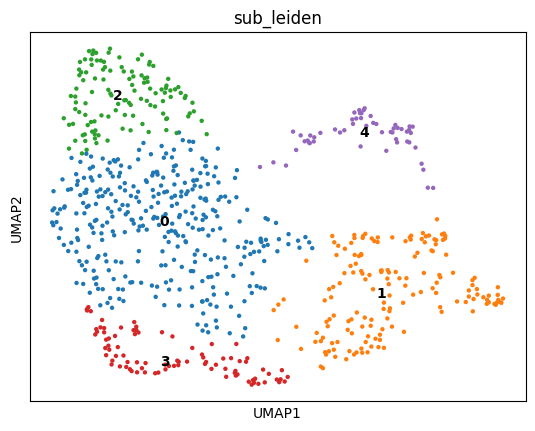

In [48]:
sc.pl.umap(
    adata_sub,
    color="sub_leiden",
    legend_loc="on data",
    size=40)

4. Найдите маркерные гены новых субкластеров.

In [49]:
sc.tl.rank_genes_groups(
    adata_sub,
    groupby="sub_leiden",
    method="wilcoxon",
    reference="rest",
    use_raw=False,
    tie_correct=True,
    corr_method="benjamini-hochberg",
    pts=True,
    key_added="sub_wilcoxon")

In [50]:
subclusters = list(adata_sub.obs["sub_leiden"].cat.categories)

for cluster in subclusters:
    markers = sc.get.rank_genes_groups_df(
        adata_sub,
        group=cluster,
        key="sub_wilcoxon")

    markers["gene"] = markers["names"].map(
        adata_sub.var["feature_name"])

    print(f"\nСубкластер {cluster}")

    display(markers[
            ["gene", "logfoldchanges", "pvals_adj",
             "pct_nz_group", "pct_nz_reference"]
        ].head(10).round(3))


Субкластер 0


,gene,logfoldchanges,pvals_adj,pct_nz_group,pct_nz_reference
0,LINC01122,1.522,0.0,0.908,0.670
1,LUZP2,1.641,0.0,0.953,0.722
2,RBFOX1,1.869,0.0,0.973,0.736
3,CNTN5,1.243,0.0,0.991,0.938
4,UNC5D,1.776,0.0,0.908,0.632
5,PTPRO,1.011,0.0,0.941,0.860
6,MPPED1,1.708,0.0,0.712,0.382
7,PBX1,1.318,0.0,0.967,0.812
8,SOX5,0.976,0.0,0.979,0.895
9,SOX2-OT,1.205,0.0,0.997,0.964



Субкластер 1


,gene,logfoldchanges,pvals_adj,pct_nz_group,pct_nz_reference
0,CNTN4,5.699,0.0,0.728,0.050
1,GRM7,4.354,0.0,0.864,0.186
2,NELL1,5.092,0.0,0.654,0.067
3,ASIC2,3.988,0.0,0.840,0.193
4,NETO2,3.738,0.0,0.944,0.336
5,ADRA1B,5.185,0.0,0.549,0.029
6,GALNT13,3.640,0.0,0.852,0.205
7,GALNTL6,4.072,0.0,0.809,0.176
8,CRH,4.671,0.0,0.599,0.067
9,PTPRE,4.028,0.0,0.630,0.082



Субкластер 2


,gene,logfoldchanges,pvals_adj,pct_nz_group,pct_nz_reference
0,CASC15,1.664,0.0,0.991,0.860
1,SOX2-OT,1.577,0.0,1.000,0.975
2,EPHA5,1.607,0.0,0.957,0.816
3,PDZRN3,1.205,0.0,0.983,0.942
4,ZNF704,1.230,0.0,0.932,0.849
5,MALAT1,0.366,0.0,1.000,1.000
6,ADK,1.665,0.0,0.838,0.598
7,ZBTB20,1.310,0.0,0.974,0.850
8,SOX11,1.386,0.0,0.795,0.649
9,IL7,1.173,0.0,0.889,0.768



Субкластер 3


,gene,logfoldchanges,pvals_adj,pct_nz_group,pct_nz_reference
0,NXPH1,4.986,0.0,0.602,0.042
1,TMEM132D,4.967,0.0,0.500,0.034
2,ZNF804B,4.172,0.0,0.614,0.078
3,HAPLN1,3.717,0.0,0.636,0.087
4,MYO16,3.299,0.0,0.886,0.224
5,PTPRM,3.405,0.0,0.818,0.234
6,GRIP1,2.474,0.0,1.000,0.678
7,TMEM132B,3.026,0.0,0.784,0.228
8,IL1RAPL2,3.294,0.0,0.773,0.221
9,LINC00299,3.766,0.0,0.534,0.093



Субкластер 4


,gene,logfoldchanges,pvals_adj,pct_nz_group,pct_nz_reference
0,BMPR1B,5.329,0.0,0.833,0.041
1,OBI1-AS1,6.466,0.0,0.722,0.030
2,LINC01515,6.760,0.0,0.556,0.009
3,TNC,5.785,0.0,0.815,0.050
4,BRINP3,5.542,0.0,0.704,0.030
5,SHROOM3,5.452,0.0,0.630,0.024
6,PRKG1,5.259,0.0,0.741,0.050
7,LINC02649,5.672,0.0,0.556,0.018
8,NEAT1,5.211,0.0,0.963,0.125
9,CDH20,5.020,0.0,0.722,0.050


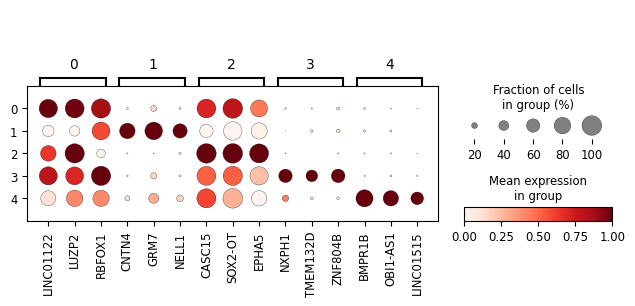

In [51]:
sc.pl.rank_genes_groups_dotplot(
    adata_sub,
    key="sub_wilcoxon",
    groupby="sub_leiden",
    n_genes=3,
    gene_symbols="feature_name",
    use_raw=False,
    standard_scale="var",
    dendrogram=False)

5. Попробуйте определить более узкие клеточные типы или состояния на основании маркеров.

Субкластер 0 (337 ядер) характеризуется повышенной экспрессией RBFOX1, LUZP2 и LINC01122 (RBFOX1 участвует в регуляции альтернативного сплайсинга в нервной системе. Данная популяция может отличаться особенностями регуляции нейрональной экспрессии)

Субкластер 1 (162 ядра) характеризуется экспрессией CNTN4, GRM7, NELL1 и CRH (CRH связан с нейроэндокринной регуляцией и встречается в некоторых популяциях тормозных интернейронов)

Субкластер 2 (117 ядер) отличается экспрессией CASC15, SOX2-OT, EPHA5 и SOX11 (некоторые из этих генов связаны с развитием нервной системы, поэтому субкластер может отражать особенности созревания нейронов)

Субкластер 3 (88 ядер) характеризуется повышенной экспрессией NXPH1, TMEM132D и ZNF804B (NXPH1 кодирует белок, участвующий во взаимодействиях между нейронами)

Субкластер 4 (54 ядра) отличается высокой экспрессией BMPR1B, TNC и BRINP3 (эти гены связаны с развитием нервной системы, клеточной дифференцировкой и организацией внеклеточного матрикса)

**Вопросы:**
- Удалось ли разделить исходную популяцию на биологически интерпретируемые субпопуляции?

    Да, исходный кластер 4 был разделён на пять субкластеров, различающихся профилями экспрессии генов. Для некоторых групп удалось предположить особенности клеточных типов или функциональных состояний, например CRH+ и NXPH1+ нейрональные популяции

- Какие гены отличают новые субкластеры?

    См. выше
- Почему эти различия могли быть незаметны при первоначальной кластеризации всех клеток?

    При первоначальной кластеризации анализировались все клеточные популяции, поэтому наибольший вклад в разделение могли вносить гены, отличающие основные типы клеток друг от друга. При субкластеризации анализ ограничивается одной популяцией, а высоковариабельные гены отбираются повторно, благодаря этому становятся заметнее более тонкие различия экспрессии, связанные с клеточными подтипами, стадиями созревания или функциональными состояниями

### Задание 7. Генные программы (Gene Scores)

Выберите **три набора генов**, соответствующих различным биологическим функциям или клеточным состояниям.


Для анализа выберем программы, соответствующие биологическим процессам развития головного мозга человека:

1) Миелинизация: MBP, PLP1, MOBP, MAG, MOG (гены связаны с формированием и поддержанием миелиновой оболочки и характерны для олигодендроцитов)

2) Развитие нейронов: DCX, STMN2, TUBB3, SOX11, NEUROD1 (гены участвуют в нейрональной дифференцировке и связаны с незрелыми нейрональными состояниями)

3) Пролиферация: MKI67, TOP2A, PCNA, TYMS, MCM2 (гены связаны с клеточным циклом, репликацией ДНК и клеточным делением)

1. Рассчитайте оценки всех трёх программ с помощью `sc.tl.score_genes()`.

Сачала опоставим названия с Ensembl ID, чтобы функция смогла найти нужные гены

In [52]:
GENE_SETS = {"Myelination": ["MBP", "PLP1", "MOBP", "MAG", "MOG"],
    "Neuronal_development": ["DCX", "STMN2", "TUBB3", "SOX11", "NEUROD1"],
    "Proliferation": ["MKI67", "TOP2A", "PCNA", "TYMS", "MCM2"]}

In [53]:
for name, genes in GENE_SETS.items():
    present = adata.var["feature_name"].isin(genes)
    gene_ids = adata.var_names[present].tolist()

    print(name)
    print("Найдены гены:", adata.var.loc[present, "feature_name"].tolist())

    if len(gene_ids) < 3:
        raise ValueError(f"Слишком мало генов для {name}")

    sc.tl.score_genes(
        adata,
        gene_list=gene_ids,
        score_name=f"{name}_score",
        use_raw=False)

Myelination
Найдены гены: ['MOBP', 'MBP', 'MAG', 'PLP1']
Neuronal_development
Найдены гены: ['SOX11', 'NEUROD1', 'STMN2', 'TUBB3', 'DCX']
Proliferation
Найдены гены: ['MCM2', 'MKI67', 'TOP2A', 'TYMS', 'PCNA']


In [54]:
score_cols = ["Myelination_score",
    "Neuronal_development_score",
    "Proliferation_score"]

adata.obs[score_cols].describe().round(3)

,Myelination_score,Neuronal_development_score,Proliferation_score
count,7415.000,7415.000,7415.000
mean,0.067,0.054,-0.001
std,0.553,0.411,0.103
min,-0.440,-0.460,-0.113
25%,-0.249,-0.255,-0.037
50%,-0.051,-0.062,-0.024
75%,0.178,0.193,-0.011
max,4.167,1.931,1.922


2. Постройте UMAP, раскрашенные по значениям каждого score.

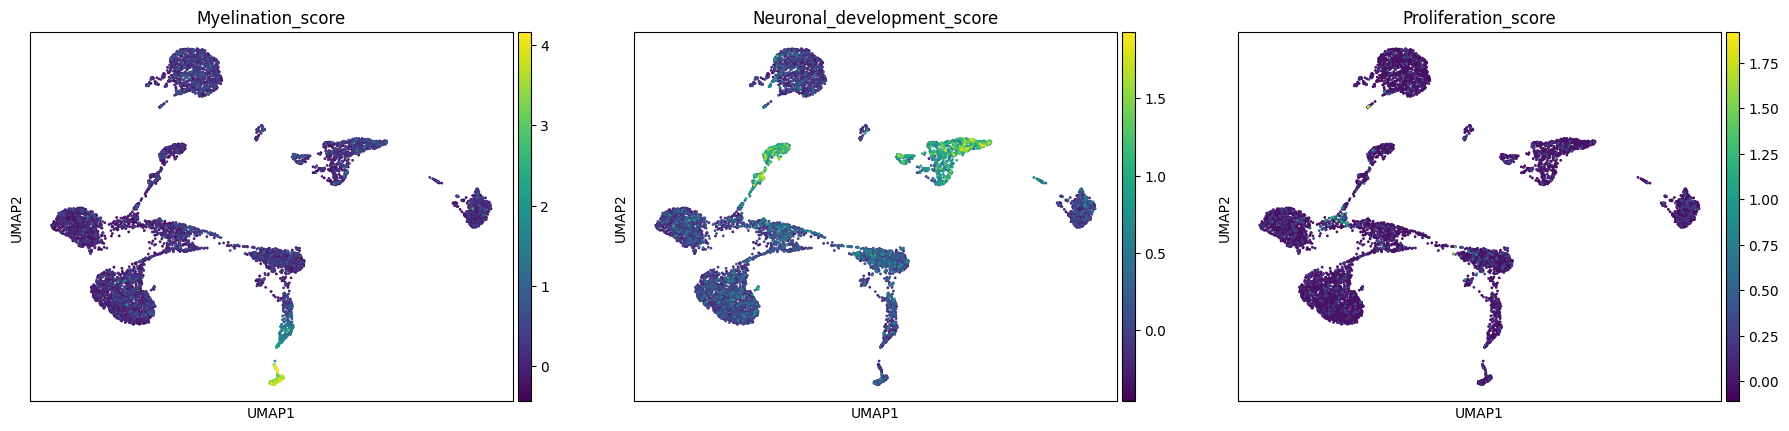

In [55]:
sc.pl.umap(
    adata,
    color=score_cols,
    ncols=3)

3. Постройте violin plots распределения scores по аннотированным клеточным типам.

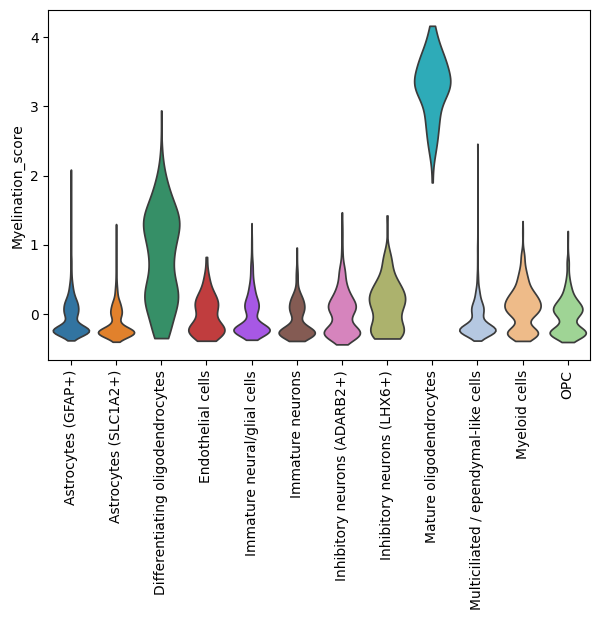

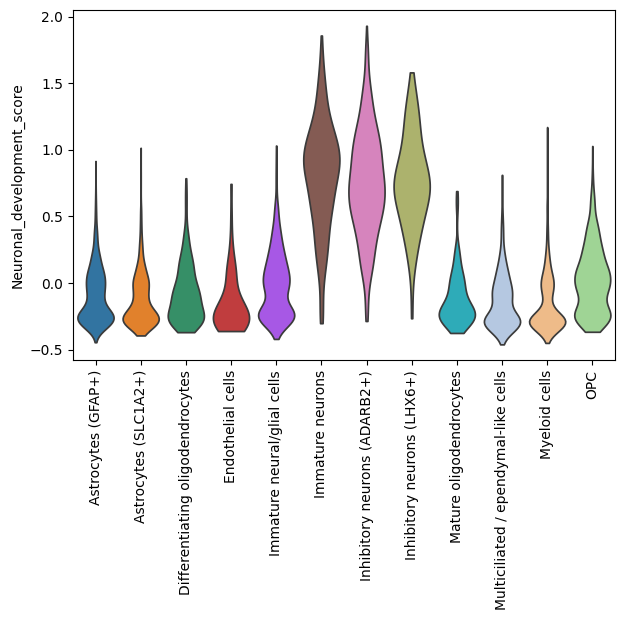

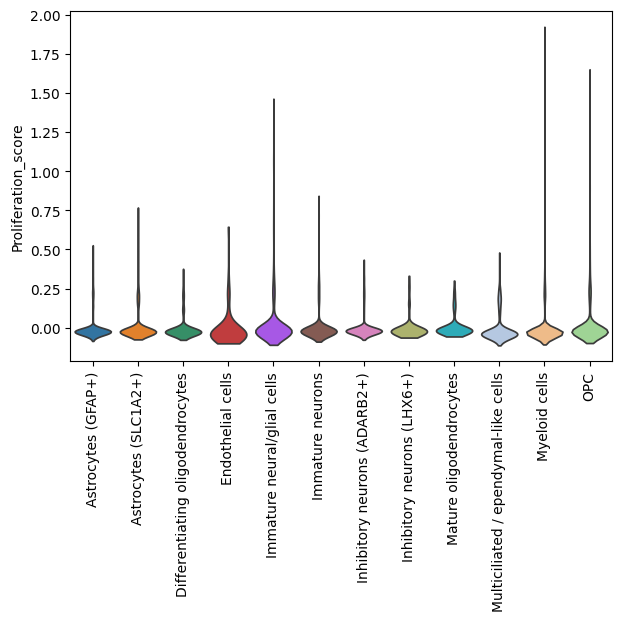

In [56]:
for score in score_cols:
    sc.pl.violin(
        adata,
        keys=score,
        groupby="manual_cell_type",
        stripplot=False,
        rotation=90)

4. Определите, в каких клеточных популяциях каждая программа выражена сильнее всего.

Для трёх выбранных генных программ были рассчитаны Gene Scores: миелинизация, развитие нейронов и пролиферация

* Миелинизация (Myelination_score)

Для программы миелинизации из пяти выбранных генов в датасете были обнаружены четыре (MBP, PLP1, MOBP, MAG), которые использовались для расчёта Gene Score

Наиболее высокие значения наблюдаются у Mature oligodendrocytes и Differentiating oligodendrocytes. В меньшей степени  у Inhibitory neurons (LHX6+) и некоторых других популяций

По UMAP видно, что максимальные значения Myelination_score сосредоточены в области, соответствующей олигодендроцитарной линии

* Развитие нейронов (Neuronal_development_score)

Наиболее высокие значения наблюдаются у Immature neurons, Inhibitory neurons (ADARB2+), Inhibitory neurons (LHX6+)

По UMAP видно, что программа нейронального развития выражена в нейрональных популяциях, особенно в незрелых нейронах и тормозных нейронах. Это согласуется с наличием в данных развивающихся нейрональных состояний

* Пролиферация (Proliferation_score)

Значения Proliferation_score в целом низкие почти во всех популяциях. На violin plots заметно, что выраженной крупной популяции активно делящихся клеток нет и  в некоторых типах клеток встречаются отдельные ядра с повышенными значениями score

Таким образом пролиферативная программа в датасете выражена слабо и не формирует отдельный крупный кластер делящихся клеток

5. Сравните полученные результаты с аннотацией клеточных типов.

Полученные Gene Scores хорошо согласуются с ручной аннотацией

* Высокий Myelination_score у Mature oligodendrocytes и Differentiating oligodendrocytes подтверждает правильность их аннотации как клеток олигодендроцитарной линии, связанных с миелинизацией

* Высокий Neuronal_development_score у Immature neurons подтверждает, что эта популяция действительно соответствует незрелым нейронам

* Повышенные значения Neuronal_development_score у Inhibitory neurons (ADARB2+) и Inhibitory neurons (LHX6+) показывают, что эти клетки также связаны с нейрональной программой, хотя могут находиться на разных стадиях созревания


**Главный вопрос:** как информацию о генных программах можно использовать для уточнения ручной аннотации клеток?

Генные программы помогают проверить ручную аннотацию, показывая какие биологические процессы характерны для разных клеточных популяций. Например в наших данных высокая оценка программы миелинизации характерна для зрелых олигодендроцитов, а программы нейронального развития для незрелых нейронов. Это подтверждает предполагаемые клеточные типы и помогает различать стадии их созревания (однако gene scores необходимо интерпретировать совместно с маркерными генами)

### Задание 8. Итоговые результаты и выводы

В ходе работы был проанализирован открытый snRNA-seq датасет EC Stream Region at 14 days of age из энторинальной коры головного мозга человека

1. Какие основные клеточные популяции удалось обнаружить?
    - астроциты
    - миелоидные клетки
    - незрелые нейральные/глиальные клетки
    - незрелые нейроны
    - тормозные нейроны
    - предшественники олигодендроцитов (OPC)
    - дифференцирующиеся и зрелые олигодендроциты
    - эпендимоподобные/реснитчатые клетки
    - эндотелиальные клетки
2. Какие маркерные гены позволили их идентифицировать?
    - астроциты - GFAP, CD44, SLC1A2
    - миелоидные клетки - CSF3R, TLR2, MS4A7
    - тормозные нейроны - ADARB2, DLX6-AS1, LHX6, KCNC2
    - OPC - PDGFRA, LHFPL3
    - дифференцирующиеся олигодендроциты - GPR17, ENPP6, MYRF
    - зрелые олигодендроциты - MOBP, OPALIN, MAL
    - эпендимоподобные клетки - DNAAF1, CFAP157, DNAH5
    - эндотелиальные клетки - EMCN, CD34, ESAM
3. Насколько согласуются ручная и автоматическая аннотации?

    Ручная и автоматическая аннотации в целом хорошо согласуются на уровне основных клеточных линий. Наиболее хорошее совпадение наблюдалось для астроцитов, миелоидных клеток, OPC, дифференцирующихся и зрелых олигодендроцитов. Наибольшие расхождения были отмечены для эпендимоподобных клеток и части тормозных нейронов. Вероятно это связано с тем, что модель CellTypist была обучена на другом типе мозговой ткани и другом возрастном материале

4. Что удалось обнаружить при субкластеризации?

    Для субкластеризации был выбран кластер тормозных нейронов. После повторного анализа он разделился на 5 субкластеров, различающихся по профилям экспрессии (были выделены группы с характерными маркерами)

    Это показывает, что внутри исходной популяции тормозных нейронов присутствует дополнительная неоднородность, которая могла отражать разные подтипы клеток или функциональные состояния
5. Какие дополнительные сведения о клетках дали генные программы?

    Анализ генных программ показал:
     - программа миелинизации наиболее выражена у зрелых и дифференцирующихся олигодендроцитов
     - программа нейронального развития наиболее выражена у незрелых нейронов и части тормозных нейронов
     - программа пролиферации в целом выражена слабо, что указывает на отсутствие крупной популяции активно делящихся клеток

    Gene Scores помогли подтвердить ручную аннотацию и различить стадии дифференцировки клеток олигодендроцитарной линии